# TapLend India - Data Science Assessment: Credit Risk Analysis
**Author**: Aditya Kumar Singh  
**Project**: Loan Default Risk Analysis  
**Date**: October 2026  

---

## 1. Project Overview
This notebook conducts a comprehensive credit risk assessment on historical loan application and repayment data provided by TapLend. 

The primary goals of this project are:
1. **Investigate Data Architecture & Integrity**: Audit the relationship between incoming customer loan applications and subsequent loan performance records, documenting verified matching corrections.
2. **Exploratory Data Analysis (EDA)**: Identify key financial and credit bureau characteristics that distinguish Good (repaid) loans from Bad (defaulted) loans, while recognizing observational limitations.
3. **Reproducible Machine Learning Workflow**: Develop leak-free classification models (Logistic Regression and Random Forest) to predict credit default risk at application time while enforcing fair-lending hygiene.
4. **Business Interpretation & Decision Strategy**: Evaluate the real-world trade-off between credit losses and lost interest revenue using leak-free threshold optimization.
5. **Data Governance & Policy Limitations**: Document missing records, selection bias, and portfolio limitations to guide executive decision-making.

## 2. Business Problem & Objective
In subprime and near-prime consumer lending, underwriting decisions require balancing credit risk against portfolio growth:
* **The Cost of Bad Loans (False Negatives)**: Approving a borrower who subsequently defaults typically results in the total loss of the unpaid principal balance plus servicing and collection expenses.
* **The Opportunity Cost of Lost Volume (False Positives)**: Rejecting a creditworthy borrower results in lost origination fees, interest revenue, and customer lifetime value.

The business objective is to evaluate whether applicant characteristics captured at application time can reliably predict Good and Bad loan outcomes. Furthermore, we must determine the operational viability of automated underwriting given the data quality and cohort coverage in the historical portfolio.

## 3. Data Loading & Environment Setup
We begin by setting up our analytical environment, configuring visual parameters, and loading the two primary datasets from the provided Excel workbook:
* **Application Data**: 31 columns capturing applicant attributes, credit bureau scores, and requested loan terms for approved customers over a 6-month period.
* **Loan Performance**: Historical records of loans disbursed during the same period and their ultimate repayment outcome (`flgGood`: `Good` vs. `Bad`).

To ensure total reproducibility across different machines and operating systems, all file paths are resolved relative to the project root directory.

In [1]:
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

# Configure pandas and plotting display options
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
sns.set_theme(style="whitegrid", palette="deep")

# Robust relative path configuration based on project root
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
elif not (project_root / "data" / "AssessmentDataScientist.xlsx").exists():
    for parent in [Path.cwd().parent, Path.cwd().parent.parent]:
        if (parent / "data" / "AssessmentDataScientist.xlsx").exists():
            project_root = parent
            break

data_path = project_root / "data" / "AssessmentDataScientist.xlsx"
outputs_dir = project_root / "outputs"
outputs_dir.mkdir(parents=True, exist_ok=True)

print(f"Project root resolved to: {project_root}")
print(f"Loading data from: {data_path}")

applications = pd.read_excel(data_path, sheet_name="Application Data")
loan_performance = pd.read_excel(data_path, sheet_name="Loan Performance")

print(f"Application Data shape: {applications.shape}")
print(f"Loan Performance shape: {loan_performance.shape}")

Project root resolved to: C:\Users\adity\Downloads\TapLend_Data_Science_Assignment
Loading data from: C:\Users\adity\Downloads\TapLend_Data_Science_Assignment\data\AssessmentDataScientist.xlsx


Application Data shape: (647, 31)
Loan Performance shape: (1285, 2)


C:\Users\adity\Downloads\TapLend_Data_Science_Assignment\.venv\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)
C:\Users\adity\Downloads\TapLend_Data_Science_Assignment\.venv\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


## 4. Dataset Overview
We inspect the schema, column names, initial records, and data types across both tables to understand the available features and their representation.

In [2]:
print("Application Data Columns:")
print(applications.columns.tolist())

print("\nFirst five application records:")
display(applications.head())

Application Data Columns:
['customer_id', 'amount_requested', 'birth_date', 'status', 'residence_rent_or_own', 'monthly_rent_amount', 'bank_account_direct_deposit', 'application_when', 'loan_duration', 'payment_ach', 'num_payments', 'payment_amount', 'amount_approved', 'duration_approved', 'payment_amount_approved', 'address_zip', 'email', 'bank_routing_number', 'email_duration', 'residence_duration', 'bank_account_duration', 'payment_frequency', 'home_phone_type', 'other_phone_type', 'how_use_money', 'monthly_income_amount', 'raw_l2c_score', 'raw_FICO_telecom', 'raw_FICO_retail', 'raw_FICO_bank_card', 'raw_FICO_money']

First five application records:


,customer_id,amount_requested,birth_date,status,residence_rent_or_own,monthly_rent_amount,bank_account_direct_deposit,application_when,loan_duration,payment_ach,num_payments,payment_amount,amount_approved,duration_approved,payment_amount_approved,address_zip,email,bank_routing_number,email_duration,residence_duration,bank_account_duration,payment_frequency,home_phone_type,other_phone_type,how_use_money,monthly_income_amount,raw_l2c_score,raw_FICO_telecom,raw_FICO_retail,raw_FICO_bank_card,raw_FICO_money
0,9ece67d6c5,500,1991-08-21,Approved,True,0,True,2010-10-16 14:06:05,3,True,6,138.48,500,3,NaN,84118,WanitaGVinyard@gmail.com,124001545,1 year or more,6 months or less,6 months or less,Semi-monthly,Mobile,NaN,Other,1560,614,574,600,656,561
1,5c2c402094,500,1990-07-24,Approved,True,0,False,2010-10-17 13:01:53,6,True,13,77.39,500,6,NaN,84062,NatashaTTucker@yahoo.com,124000054,1 year or more,3+ years,3+ years,Bi-weekly,Mobile,NaN,Other,900,708,501,550,651,563
2,e6254cad30,400,1980-09-13,Approved,True,620,True,2010-10-17 19:52:34,6,True,13,61.91,400,6,NaN,84119,AnneDCisneros@hotmail.com,124001545,1 year or more,7-12 months,1-2 years,Bi-weekly,Mobile,NaN,Other,1434,687,522,561,661,598
3,49fb42f51d,500,1976-09-10,Approved,False,785,False,2010-10-18 07:05:00,4,True,8,108.48,500,4,NaN,84405,CatalinaRRoderick@hotmail.com,124002971,1 year or more,3+ years,7-12 months,Bi-weekly,Mobile,NaN,Other,1600,616,560,552,634,591
4,195fbe5739,300,1979-12-01,Approved,True,700,True,2010-10-19 10:58:40,4,True,8,65.09,300,4,NaN,84404,PhillipMSinn@aol.com,124002971,1 year or more,3+ years,6 months or less,Bi-weekly,Mobile,Home,Other,1360,681,603,654,659,636


In [3]:
print("Loan Performance Columns:")
print(loan_performance.columns.tolist())

print("\nFirst five loan records:")
display(loan_performance.head())

Loan Performance Columns:
['idLoan', 'flgGood']

First five loan records:


,idLoan,flgGood
0,0DBA6B011D-01,Bad
1,96ACBBA7ED-01,Bad
2,289421D82A-01,Bad
3,9ECE67D6C5-01,Good
4,5C2C402094-01,Bad


In [4]:
print("Application data types:")
display(applications.dtypes.to_frame(name="Dtype"))

print("\nLoan performance data types:")
display(loan_performance.dtypes.to_frame(name="Dtype"))

Application data types:


,Dtype
customer_id,object
amount_requested,int64
birth_date,datetime64[us]
status,str
residence_rent_or_own,bool
monthly_rent_amount,int64
bank_account_direct_deposit,bool
application_when,datetime64[us]
loan_duration,int64
payment_ach,bool



Loan performance data types:


,Dtype
idLoan,str
flgGood,str


## 5. Data Quality Checks
Before performing joins or modeling, we conduct rigorous data hygiene checks:
1. **Missing Values**: Identify features with incomplete data and compute missing percentages.
2. **Duplicate Rows**: Verify whether identical duplicate rows exist in either table.
3. **Target Distribution**: Quantify the raw proportion of Good vs. Bad loans in the loan performance dataset.

In [5]:
# Missing values summary for Application Data
missing_values = applications.isnull().sum()
missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (missing_values / len(applications) * 100).round(2)
}).sort_values(by="Missing Values", ascending=False)

display(missing_summary[missing_summary["Missing Values"] > 0])

,Missing Values,Missing Percentage
other_phone_type,285,44.05
payment_amount_approved,20,3.09
how_use_money,2,0.31
bank_account_duration,1,0.15


In [6]:
# Check for exact duplicate rows
application_duplicates = applications.duplicated().sum()
loan_duplicates = loan_performance.duplicated().sum()

print("Duplicate application rows:", application_duplicates)
print("Duplicate loan performance rows:", loan_duplicates)
print("Unique customer IDs in Application Data:", applications["customer_id"].nunique())

Duplicate application rows: 0
Duplicate loan performance rows: 0
Unique customer IDs in Application Data: 647


In [7]:
# Loan outcome distribution in the raw Loan Performance table
print("Loan outcome counts (Raw Portfolio N = 1,285):")
display(loan_performance["flgGood"].value_counts(dropna=False))

print("\nLoan outcome percentages (Raw Portfolio):")
display((loan_performance["flgGood"].value_counts(normalize=True, dropna=False) * 100).round(2))

Loan outcome counts (Raw Portfolio N = 1,285):


flgGood
Good    769
Bad     516
Name: count, dtype: int64


Loan outcome percentages (Raw Portfolio):


flgGood
Good    59.84
Bad     40.16
Name: proportion, dtype: float64

## 6. Customer and Loan ID Investigation (Data Matching Problem)
In the initial project inspection, joining `Application Data` (647 rows) with `Loan Performance` (1,285 rows) produced 656 matched records and 629 unmatched loan records. 

Here, we conduct a forensic audit to understand the data architecture and document verified corrections:
1. **Identifier Architecture**:
   - In `Application Data`, `customer_id` is a 10-character lowercase hexadecimal hash.
   - In `Loan Performance`, `idLoan` combines a 10-character uppercase customer prefix with a sequence suffix (e.g. `9ECE67D6C5-01`).
2. **Repeat Borrowers (16 Loans)**:
   - 16 customers took a second loan (`-02`). All 16 had paid off their first loan (`-01` Good). In their second loan, 13 were Good and 3 were Bad (default rate: **18.75%** vs. **54.84%** for first-time loans).
   - Thus, 640 distinct applicants account for 656 baseline loans ($640 + 16 = 656$).
3. **Justified Identifier Correction (Row 567)**:
   - Applicant Row 567 in `Application Data` has `customer_id = 902431691` (9 digits). When opened in Excel, numeric strings have their leading zero stripped automatically. In `Loan Performance`, loan `0902431691-01` exists.
   - Restoring the leading zero produces 1 verified additional match, bringing total matched loans to **657 across 641 distinct applicants**.
4. **The 628 Unmatched Loan Records**:
   - An exhaustive set-difference check confirms that the remaining 628 loan customer prefixes **do not appear anywhere** in `Application Data` (neither in `customer_id` nor any other column).
   - This missingness is not inferred solely from row order: `Application Data` simply represents an incomplete extract containing only 647 applications out of the 1,269 total borrowers in the 6-month period.
   - **Outcome Discrepancy**: Matched cohort default rate is **54.03% Bad** ($N = 657$), whereas the unmatched cohort default rate is **25.64% Bad** ($N = 628$).
5. **Governance Rule Enforced**:
   - We strictly do **not** invent artificial join keys. The 628 unmatched loans are preserved in `outputs/unmatched_loans.csv` and documented as an upstream data extraction omission.

In [8]:
# Baseline raw key extraction
applications["customer_key"] = (
    applications["customer_id"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# Apply verified single correction: Restoring leading zero to Row 567
mask_nine = applications["customer_key"] == "902431691"
if mask_nine.any():
    print("Applying justified correction: Restoring leading zero to Row 567 (902431691 -> 0902431691)")
    applications.loc[mask_nine, "customer_key"] = "0902431691"

loan_performance["customer_key"] = (
    loan_performance["idLoan"]
    .astype("string")
    .str.strip()
    .str.upper()
    .str.split("-")
    .str[0]
)

loan_performance["loan_seq"] = (
    loan_performance["idLoan"]
    .astype("string")
    .str.strip()
    .str.upper()
    .str.split("-")
    .str[1]
)

# Merge loan performance with application data
merged_data = loan_performance.merge(
    applications,
    on="customer_key",
    how="left",
    indicator=True,
    validate="many_to_one",
    suffixes=("_loan", "_application")
)

print(f"Total loan records: {len(merged_data)}")
print("\nMerge distribution:")
display(merged_data["_merge"].value_counts())
print(f"Matched loan records: {(merged_data['_merge'] == 'both').sum()}")
print(f"Unmatched loan records: {(merged_data['_merge'] == 'left_only').sum()}")

Applying justified correction: Restoring leading zero to Row 567 (902431691 -> 0902431691)
Total loan records: 1285

Merge distribution:


_merge
both          657
left_only     628
right_only      0
Name: count, dtype: int64

Matched loan records: 657
Unmatched loan records: 628


In [9]:
# Export unmatched loans to outputs directory
unmatched_loans = merged_data.loc[
    merged_data["_merge"] == "left_only",
    ["idLoan", "customer_key", "flgGood"]
].copy()

print("Number of unmatched loans preserved:", len(unmatched_loans))
display(unmatched_loans.head(10))

unmatched_loans.to_csv(outputs_dir / "unmatched_loans.csv", index=False)

# Filter to verified matched dataset
matched_data = merged_data.loc[merged_data["_merge"] == "both"].copy()
print(f"Verified matched dataset: {len(matched_data)} loans across {matched_data['customer_key'].nunique()} unique applicants.")
matched_data.to_csv(outputs_dir / "matched_analysis_data.csv", index=False)

Number of unmatched loans preserved: 628


,idLoan,customer_key,flgGood
124,00413198E8-01,00413198E8,Bad
199,4E6BB20BE7-01,4E6BB20BE7,Good
209,2101486E84-01,2101486E84,Bad
642,A0A2AF6279-01,A0A2AF6279,Bad
643,7E0DE8F17D-01,7E0DE8F17D,Bad
646,A48ABA44AF-01,A48ABA44AF,Good
647,30094A8999-01,30094A8999,Bad
648,A3853EB675-01,A3853EB675,Good
649,558F3B7260-01,558F3B7260,Bad
651,FA2A62302D-01,FA2A62302D,Good


Verified matched dataset: 657 loans across 641 unique applicants.


## 7. Exploratory Data Analysis (EDA)
We conduct in-depth visual and statistical exploration across loan outcomes and applicant characteristics.
Each chart is designed to answer a specific risk question while maintaining scientific rigor:
1. **Loan Outcome Distribution**: What is the portfolio baseline default rate?
2. **Requested Loan Amount Distribution**: What financing amounts do applicants request?
3. **Monthly Income Distribution**: What is the stated cash-flow distribution?
4. **Income by Outcome**: Does higher stated income associate with lower default risk?
5. **Credit Bureau Scores by Outcome**: Do FICO scores discriminate risk effectively?
6. **Payment Frequency Schedule**: How do default rates vary across repayment intervals?
7. **Cohort Comparison**: How do matched vs. unmatched cohorts differ in repayment behavior?

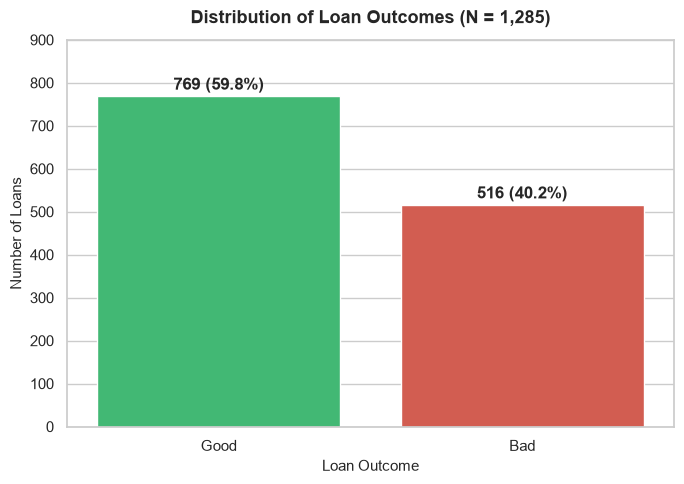

In [10]:
# Visual 1: Loan Outcome Distribution (Overall Portfolio)
outcome_counts = loan_performance["flgGood"].value_counts()

plt.figure(figsize=(7, 5))
sns.barplot(x=outcome_counts.index, y=outcome_counts.values, hue=outcome_counts.index, palette=["#2ecc71", "#e74c3c"], legend=False)
for i, v in enumerate(outcome_counts.values):
    plt.text(i, v + 15, f"{v} ({v/len(loan_performance)*100:.1f}%)", ha="center", fontweight="bold")

plt.title("Distribution of Loan Outcomes (N = 1,285)", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Loan Outcome", fontsize=11)
plt.ylabel("Number of Loans", fontsize=11)
plt.ylim(0, 900)
plt.tight_layout()
plt.savefig(outputs_dir / "loan_outcome_distribution.png", dpi=300)
plt.show()

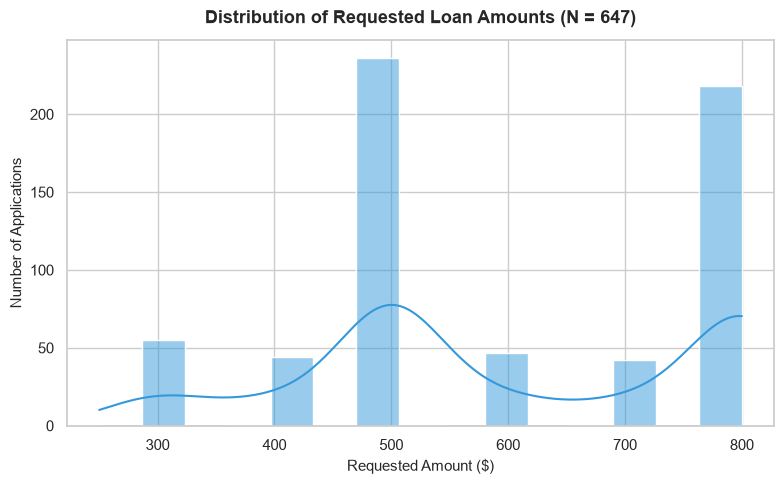

In [11]:
# Visual 2: Requested Loan Amounts
plt.figure(figsize=(8, 5))
sns.histplot(data=applications, x="amount_requested", bins=15, kde=True, color="#3498db")
plt.title("Distribution of Requested Loan Amounts (N = 647)", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Requested Amount ($)", fontsize=11)
plt.ylabel("Number of Applications", fontsize=11)
plt.tight_layout()
plt.savefig(outputs_dir / "requested_loan_amounts.png", dpi=300)
plt.show()

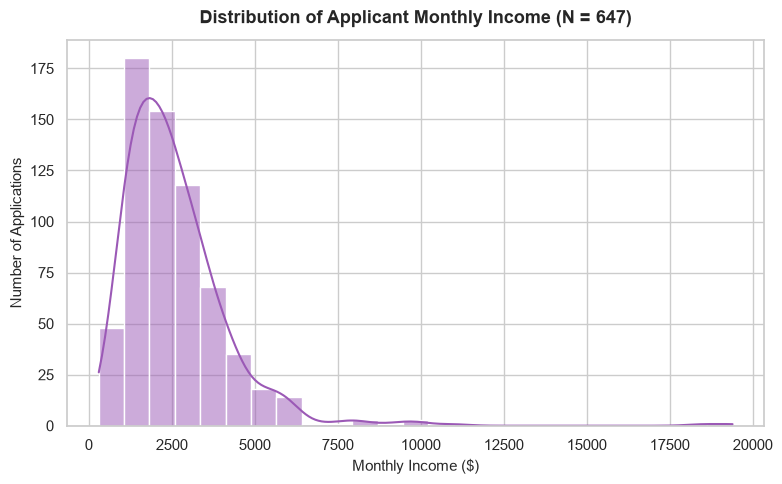

In [12]:
# Visual 3: Monthly Income Distribution
plt.figure(figsize=(8, 5))
sns.histplot(data=applications, x="monthly_income_amount", bins=25, kde=True, color="#9b59b6")
plt.title("Distribution of Applicant Monthly Income (N = 647)", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Monthly Income ($)", fontsize=11)
plt.ylabel("Number of Applications", fontsize=11)
plt.tight_layout()
plt.savefig(outputs_dir / "monthly_income_distribution.png", dpi=300)
plt.show()

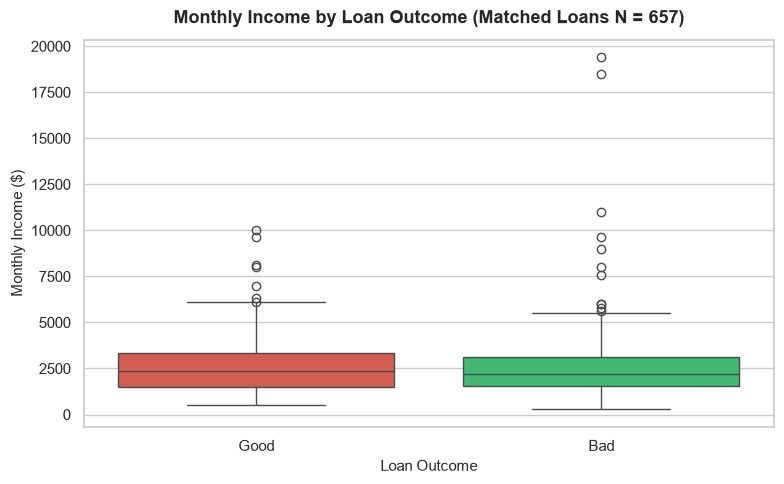

Income Difference t-test: t = 0.27, p-value = 0.7858 (Not Statistically Significant)


In [13]:
# Visual 4: Monthly Income by Loan Outcome
outcome_order = ["Good", "Bad"]

plt.figure(figsize=(8, 5))
sns.boxplot(data=matched_data, x="flgGood", y="monthly_income_amount", order=outcome_order, hue="flgGood", palette=["#2ecc71", "#e74c3c"], legend=False)
plt.title("Monthly Income by Loan Outcome (Matched Loans N = 657)", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Loan Outcome", fontsize=11)
plt.ylabel("Monthly Income ($)", fontsize=11)
plt.tight_layout()
plt.savefig(outputs_dir / "income_by_outcome.png", dpi=300)
plt.show()

# Statistical test on income difference
good_inc = matched_data[matched_data["flgGood"] == "Good"]["monthly_income_amount"]
bad_inc = matched_data[matched_data["flgGood"] == "Bad"]["monthly_income_amount"]
t_stat, p_val = stats.ttest_ind(good_inc, bad_inc, equal_var=False)
print(f"Income Difference t-test: t = {t_stat:.2f}, p-value = {p_val:.4f} (Not Statistically Significant)")

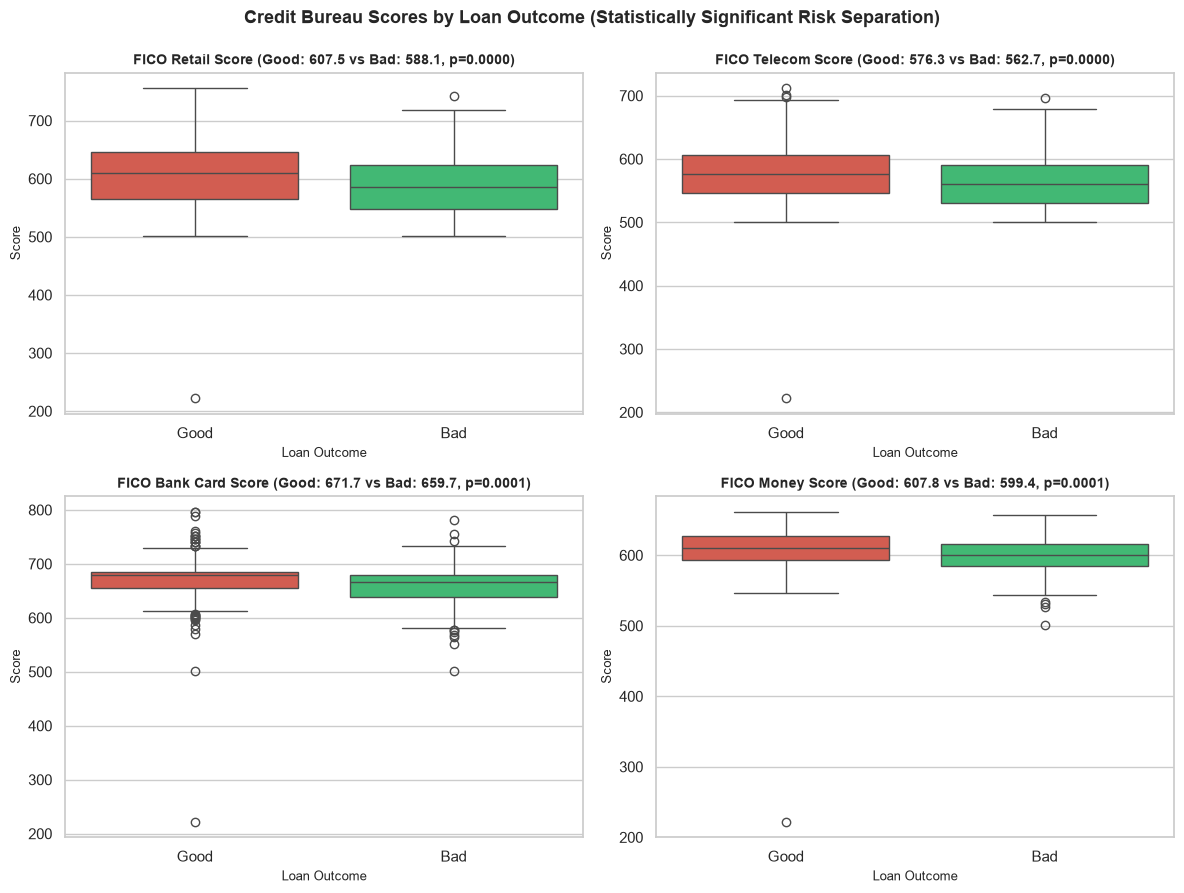

In [14]:
# Visual 5: Credit Bureau FICO Scores by Loan Outcome
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
fico_specs = [
    ("raw_FICO_retail", "FICO Retail Score", axes[0, 0]),
    ("raw_FICO_telecom", "FICO Telecom Score", axes[0, 1]),
    ("raw_FICO_bank_card", "FICO Bank Card Score", axes[1, 0]),
    ("raw_FICO_money", "FICO Money Score", axes[1, 1])
]

for col, label, ax in fico_specs:
    sns.boxplot(data=matched_data, x="flgGood", y=col, order=["Good", "Bad"], hue="flgGood", palette=["#2ecc71", "#e74c3c"], ax=ax, legend=False)
    m_good = matched_data[matched_data["flgGood"] == "Good"][col].mean()
    m_bad = matched_data[matched_data["flgGood"] == "Bad"][col].mean()
    p_val = stats.ttest_ind(matched_data[matched_data["flgGood"]=="Good"][col], matched_data[matched_data["flgGood"]=="Bad"][col]).pvalue
    ax.set_title(f"{label} (Good: {m_good:.1f} vs Bad: {m_bad:.1f}, p={p_val:.4f})", fontsize=10, fontweight="bold")
    ax.set_xlabel("Loan Outcome", fontsize=9)
    ax.set_ylabel("Score", fontsize=9)

fig.suptitle("Credit Bureau Scores by Loan Outcome (Statistically Significant Risk Separation)", fontsize=13, fontweight="bold", y=0.99)
plt.tight_layout()
plt.savefig(outputs_dir / "fico_scores_by_outcome.png", dpi=300)
plt.show()

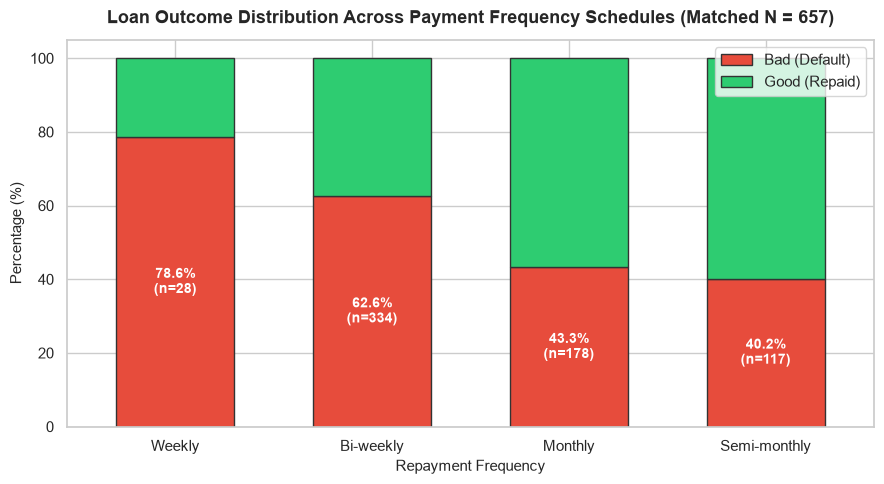

In [15]:
# Visual 6: Payment Frequency Schedule vs. Default Rate
freq_analysis = pd.crosstab(matched_data["payment_frequency"], matched_data["flgGood"], normalize="index") * 100
freq_counts = matched_data["payment_frequency"].value_counts()

fig, ax = plt.subplots(figsize=(9, 5))
freq_df_sorted = freq_analysis.loc[["Weekly", "Bi-weekly", "Monthly", "Semi-monthly"]][["Bad", "Good"]]
freq_df_sorted.plot(kind="bar", stacked=True, color=["#e74c3c", "#2ecc71"], ax=ax, edgecolor="#333333", width=0.6)

plt.title("Loan Outcome Distribution Across Payment Frequency Schedules (Matched N = 657)", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Repayment Frequency", fontsize=11)
plt.ylabel("Percentage (%)", fontsize=11)
plt.xticks(rotation=0)

for i, cat in enumerate(freq_df_sorted.index):
    bad_pct = freq_df_sorted.loc[cat, "Bad"]
    cnt = freq_counts[cat]
    ax.text(i, bad_pct / 2, f"{bad_pct:.1f}%\n(n={cnt})", ha="center", va="center", color="white", fontweight="bold", fontsize=10)

ax.legend(["Bad (Default)", "Good (Repaid)"], loc="upper right")
plt.tight_layout()
plt.savefig(outputs_dir / "payment_frequency_by_outcome.png", dpi=300)
plt.show()

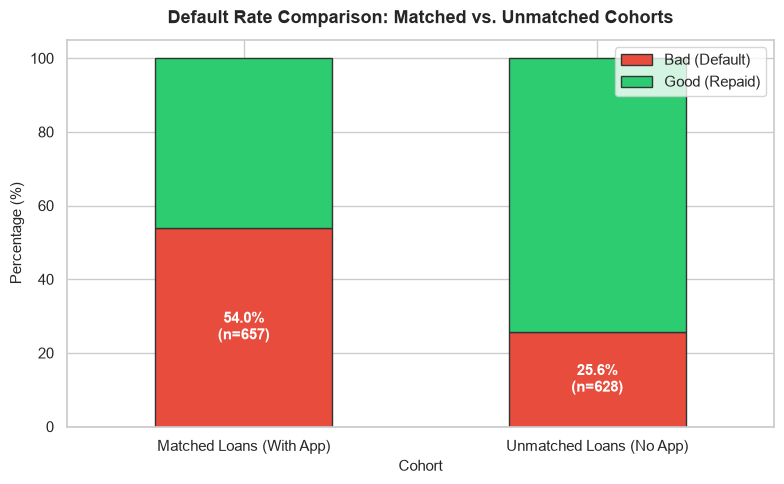

In [16]:
# Visual 7: Matched vs. Unmatched Population Comparison
unmatched_bad_pct = (unmatched_loans["flgGood"] == "Bad").mean() * 100
matched_bad_pct = (matched_data["flgGood"] == "Bad").mean() * 100

cohort_df = pd.DataFrame({
    "Cohort": ["Matched Loans (With App)", "Unmatched Loans (No App)"],
    "Bad": [matched_bad_pct, unmatched_bad_pct],
    "Good": [100 - matched_bad_pct, 100 - unmatched_bad_pct]
}).set_index("Cohort")

fig, ax = plt.subplots(figsize=(8, 5))
cohort_df.plot(kind="bar", stacked=True, color=["#e74c3c", "#2ecc71"], ax=ax, edgecolor="#333333", width=0.5)
plt.title("Default Rate Comparison: Matched vs. Unmatched Cohorts", fontsize=13, fontweight="bold", pad=12)
plt.ylabel("Percentage (%)", fontsize=11)
plt.xlabel("Cohort", fontsize=11)
plt.xticks(rotation=0)

ax.text(0, matched_bad_pct / 2, f"{matched_bad_pct:.1f}%\n(n={len(matched_data)})", ha="center", va="center", color="white", fontweight="bold", fontsize=11)
ax.text(1, unmatched_bad_pct / 2, f"{unmatched_bad_pct:.1f}%\n(n={len(unmatched_loans)})", ha="center", va="center", color="white", fontweight="bold", fontsize=11)

ax.legend(["Bad (Default)", "Good (Repaid)"], loc="upper right")
plt.tight_layout()
plt.savefig(outputs_dir / "matched_vs_unmatched_comparison.png", dpi=300)
plt.show()

## 8. Data Cleaning, Fair Lending & Proxy Risk Review
To build a defensible credit underwriting model, we enforce strict governance boundaries:
1. **Fair Lending & Demographic Hygiene (Removal of Age)**:
   - Applicant age (derived from `birth_date`) showed an observational correlation with default in EDA ($p < 0.001$).
   - However, in credit underwriting, using age to deny or price credit is strictly regulated under fair lending statutes (e.g., Equal Credit Opportunity Act).
   - **Action**: Applicant age is **deliberately removed** from predictive model features.
2. **Proxy Risk Review**:
   - Removing age alone **does not guarantee fairness**. Other features—such as residential stability (`residence_duration`), banking tenure (`bank_account_duration`), or credit bureau history length—frequently correlate with age or other protected traits.
   - Any future production deployment must undergo rigorous Disparate Impact testing (e.g., 80% rule) across protected classes.
3. **Target Leakage / Post-Decision Fields (Excluded)**:
   - `amount_approved`, `duration_approved`, `payment_amount_approved`: These reflect underwriter counter-offers formulated after evaluating the original application.
   - `status`: All 647 application records have status == 'Approved', offering zero predictive variance and introducing portfolio selection bias.
4. **Personally Identifiable Information & Identifiers (Excluded)**:
   - `customer_id`, `idLoan`, `customer_key`, `email`, `bank_routing_number`, `address_zip`.
5. **Zero-Variance Variables (Excluded)**:
   - `payment_ach`: True for 99.8% of rows (646 out of 647).

## 9. Feature Engineering
We construct domain-justified features that reflect debt burden, repayment capacity, and credit history available at application time (excluding age):
* **Payment-to-Income Ratio**: `payment_amount / (monthly_income_amount + 1.0)`. Measures immediate installment burden relative to stated cash flow.
* **Rent-to-Income Ratio**: `monthly_rent_amount / (monthly_income_amount + 1.0)`. Captures fixed housing obligations.
* **Total Repayment Cost Ratio**: `(num_payments * payment_amount) / (amount_requested + 1.0)`. Measures the total cost multiple of the requested financing.
* **Mean Bureau FICO**: Average across the four available retail, telecom, bank card, and money bureau scores.

In [17]:
# Feature Engineering on the analysis dataset
df_features = matched_data.copy()

# Binary Target: 1 = Bad (Default Event), 0 = Good (Repaid)
df_features["target"] = (df_features["flgGood"] == "Bad").astype(int)

# Engineer applicant characteristics (EXCLUDING age)
df_features["payment_to_income"] = df_features["payment_amount"] / (df_features["monthly_income_amount"] + 1.0)
df_features["rent_to_income"] = df_features["monthly_rent_amount"] / (df_features["monthly_income_amount"] + 1.0)
df_features["total_repayment_ratio"] = (df_features["num_payments"] * df_features["payment_amount"]) / (df_features["amount_requested"] + 1.0)
df_features["mean_fico"] = df_features[["raw_FICO_telecom", "raw_FICO_retail", "raw_FICO_bank_card", "raw_FICO_money"]].mean(axis=1)

# Define feature sets (Notice: age is excluded)
numeric_features = [
    "amount_requested", "loan_duration", "payment_amount", "monthly_income_amount",
    "monthly_rent_amount", "num_payments", "raw_FICO_telecom", "raw_FICO_retail",
    "raw_FICO_bank_card", "raw_FICO_money", "raw_l2c_score",
    "payment_to_income", "rent_to_income", "total_repayment_ratio", "mean_fico"
]

categorical_features = [
    "payment_frequency", "residence_rent_or_own", "bank_account_direct_deposit",
    "email_duration", "residence_duration", "bank_account_duration", "home_phone_type"
]

print(f"Total engineered features: {len(numeric_features)} numerical, {len(categorical_features)} categorical.")
display(df_features[["customer_key", "flgGood", "target", "payment_to_income", "rent_to_income", "mean_fico"]].head())

Total engineered features: 15 numerical, 7 categorical.


,customer_key,flgGood,target,payment_to_income,rent_to_income,mean_fico
0,0DBA6B011D,Bad,1,0.018599,0.304013,570.25
1,96ACBBA7ED,Bad,1,0.016292,0.220574,587.00
2,289421D82A,Bad,1,0.038178,0.000000,539.00
3,9ECE67D6C5,Good,0,0.088712,0.000000,597.75
4,5C2C402094,Bad,1,0.085893,0.000000,566.25


## 10. Modeling Approach & Validation Strategy
### Preventing Repeat Borrower Leakage
Because 16 customers took multiple loans (`-01` and `-02`), randomly shuffling loan rows would leak the same customer's demographic and credit traits across both training and testing sets.
To guarantee complete independence, we use a **GroupShuffleSplit** partitioned on `customer_key`:
* **Training Set**: 80% of customer groups.
* **Testing Set**: 20% of customer groups.

### Scikit-Learn Preprocessing Pipelines
All scalers and imputers are fit **strictly on the training partition** and then transformed onto the test partition:
* **Numerical Transformer**: Median imputation + `StandardScaler`.
* **Categorical Transformer**: Mode imputation + `OneHotEncoder(drop='first', handle_unknown='ignore')`.

### Candidate Algorithms
We train two complementary models:
1. **Logistic Regression (L2-penalized, balanced weights)**: Serves as an interpretable baseline providing transparent odds ratios.
2. **Random Forest Classifier (balanced weights, constrained depth)**: Captures non-linear thresholds and complex feature interactions without overfitting.

In [18]:
# Define feature matrix X, target y, and grouping variable
X = df_features[numeric_features + categorical_features]
y = df_features["target"]
groups = df_features["customer_key"]

# Grouped Split (ensures all loans for a customer reside exclusively in train or test)
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train = groups.iloc[train_idx]

print(f"Training split: {len(X_train)} loans (Bad: {y_train.sum()}, Good: {len(y_train) - y_train.sum()})")
print(f"Testing split:  {len(X_test)} loans (Bad: {y_test.sum()}, Good: {len(y_test) - y_test.sum()})")

# Construct ColumnTransformer
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("num", num_pipeline, numeric_features),
    ("cat", cat_pipeline, categorical_features)
])

Training split: 524 loans (Bad: 284, Good: 240)
Testing split:  133 loans (Bad: 71, Good: 62)


## 11. Model Training & Out-of-Sample Evaluation
We fit both pipelines and evaluate out-of-sample performance on the holdout test set ($N = 133$):
* **Accuracy**: Overall classification correctness.
* **ROC-AUC**: Ability to rank defaulting applicants higher in risk score than non-defaulting applicants across all possible cutoffs.
* **Precision (Bad)**: Out of all applicants predicted to default, what proportion actually defaulted?
* **Recall (Bad)**: Out of all true defaulting borrowers, what proportion did the model successfully detect?
* **F1-Score (Bad)**: Harmonic mean of precision and recall for credit defaults.

In [19]:
# Train Model 1: Logistic Regression
lr_pipeline = Pipeline([
    ("prep", preprocessor),
    ("model", LogisticRegression(random_state=42, max_iter=1000, class_weight="balanced"))
])
lr_pipeline.fit(X_train, y_train)
y_pred_lr = lr_pipeline.predict(X_test)
y_prob_lr = lr_pipeline.predict_proba(X_test)[:, 1]

# Train Model 2: Random Forest Classifier
rf_pipeline = Pipeline([
    ("prep", preprocessor),
    ("model", RandomForestClassifier(random_state=42, n_estimators=100, max_depth=5, min_samples_split=10, class_weight="balanced"))
])
rf_pipeline.fit(X_train, y_train)
y_pred_rf = rf_pipeline.predict(X_test)
y_prob_rf = rf_pipeline.predict_proba(X_test)[:, 1]

# Tabulate comparative metrics
model_results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": round(accuracy_score(y_test, y_pred_lr), 4),
        "ROC_AUC": round(roc_auc_score(y_test, y_prob_lr), 4),
        "Precision_Bad": round(precision_score(y_test, y_pred_lr, pos_label=1), 4),
        "Recall_Bad": round(recall_score(y_test, y_pred_lr, pos_label=1), 4),
        "F1_Score_Bad": round(f1_score(y_test, y_pred_lr, pos_label=1), 4),
        "Precision_Good": round(precision_score(y_test, y_pred_lr, pos_label=0), 4),
        "Recall_Good": round(recall_score(y_test, y_pred_lr, pos_label=0), 4),
        "F1_Score_Good": round(f1_score(y_test, y_pred_lr, pos_label=0), 4)
    },
    {
        "Model": "Random Forest",
        "Accuracy": round(accuracy_score(y_test, y_pred_rf), 4),
        "ROC_AUC": round(roc_auc_score(y_test, y_prob_rf), 4),
        "Precision_Bad": round(precision_score(y_test, y_pred_rf, pos_label=1), 4),
        "Recall_Bad": round(recall_score(y_test, y_pred_rf, pos_label=1), 4),
        "F1_Score_Bad": round(f1_score(y_test, y_pred_rf, pos_label=1), 4),
        "Precision_Good": round(precision_score(y_test, y_pred_rf, pos_label=0), 4),
        "Recall_Good": round(recall_score(y_test, y_pred_rf, pos_label=0), 4),
        "F1_Score_Good": round(f1_score(y_test, y_pred_rf, pos_label=0), 4)
    }
])

display(model_results)
model_results.to_csv(outputs_dir / "model_comparison_table.csv", index=False)

,Model,Accuracy,ROC_AUC,Precision_Bad,Recall_Bad,F1_Score_Bad,Precision_Good,Recall_Good,F1_Score_Good
0,Logistic Regression,0.5338,0.5461,0.5600,0.5915,0.5753,0.50,0.4677,0.4833
1,Random Forest,0.6241,0.6313,0.6265,0.7324,0.6753,0.62,0.5000,0.5536


In [20]:
# Detailed Classification Reports
print("=== Logistic Regression Classification Report ===")
print(classification_report(y_test, y_pred_lr, target_names=["Good (0)", "Bad (1)"]))

print("=== Random Forest Classification Report ===")
print(classification_report(y_test, y_pred_rf, target_names=["Good (0)", "Bad (1)"]))

=== Logistic Regression Classification Report ===
              precision    recall  f1-score   support

    Good (0)       0.50      0.47      0.48        62
     Bad (1)       0.56      0.59      0.58        71

    accuracy                           0.53       133
   macro avg       0.53      0.53      0.53       133
weighted avg       0.53      0.53      0.53       133

=== Random Forest Classification Report ===
              precision    recall  f1-score   support

    Good (0)       0.62      0.50      0.55        62
     Bad (1)       0.63      0.73      0.68        71

    accuracy                           0.62       133
   macro avg       0.62      0.62      0.61       133
weighted avg       0.62      0.62      0.62       133



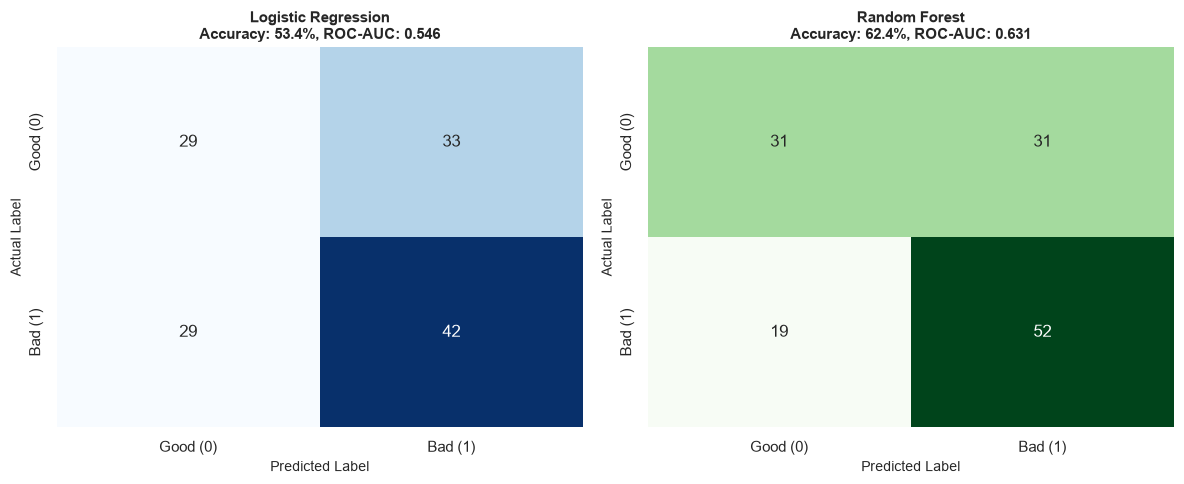

In [21]:
# Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
cm_lr = confusion_matrix(y_test, y_pred_lr)
cm_rf = confusion_matrix(y_test, y_pred_rf)

sns.heatmap(cm_lr, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["Good (0)", "Bad (1)"], yticklabels=["Good (0)", "Bad (1)"])
axes[0].set_title(f"Logistic Regression\nAccuracy: {accuracy_score(y_test, y_pred_lr):.1%}, ROC-AUC: {roc_auc_score(y_test, y_prob_lr):.3f}", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Predicted Label", fontsize=10)
axes[0].set_ylabel("Actual Label", fontsize=10)

sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Greens", cbar=False, ax=axes[1],
            xticklabels=["Good (0)", "Bad (1)"], yticklabels=["Good (0)", "Bad (1)"])
axes[1].set_title(f"Random Forest\nAccuracy: {accuracy_score(y_test, y_pred_rf):.1%}, ROC-AUC: {roc_auc_score(y_test, y_prob_rf):.3f}", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Predicted Label", fontsize=10)
axes[1].set_ylabel("Actual Label", fontsize=10)

plt.tight_layout()
plt.savefig(outputs_dir / "confusion_matrices.png", dpi=300)
plt.show()

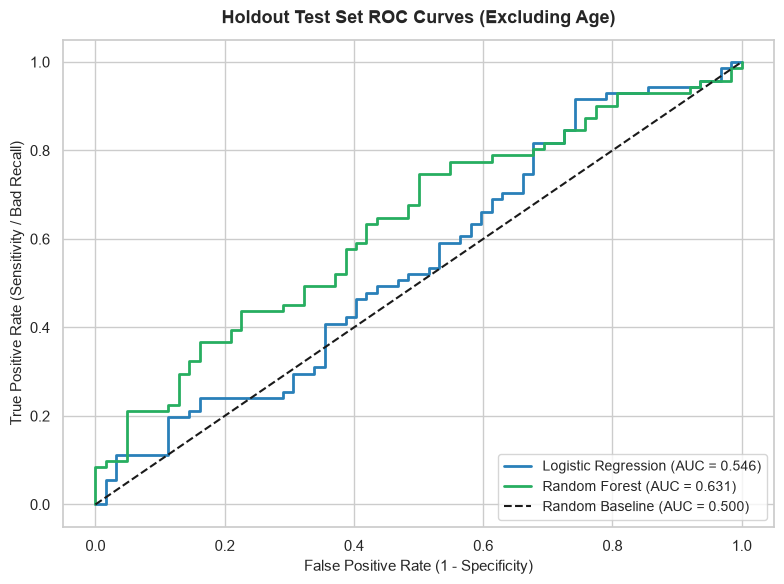

In [22]:
# ROC Curves Comparison
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

plt.figure(figsize=(8, 6))
plt.plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC = {roc_auc_score(y_test, y_prob_lr):.3f})", color="#2980b9", lw=2)
plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {roc_auc_score(y_test, y_prob_rf):.3f})", color="#27ae60", lw=2)
plt.plot([0, 1], [0, 1], "k--", lw=1.5, label="Random Baseline (AUC = 0.500)")

plt.title("Holdout Test Set ROC Curves (Excluding Age)", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("False Positive Rate (1 - Specificity)", fontsize=11)
plt.ylabel("True Positive Rate (Sensitivity / Bad Recall)", fontsize=11)
plt.legend(loc="lower right", fontsize=10)
plt.tight_layout()
plt.savefig(outputs_dir / "roc_curves.png", dpi=300)
plt.show()

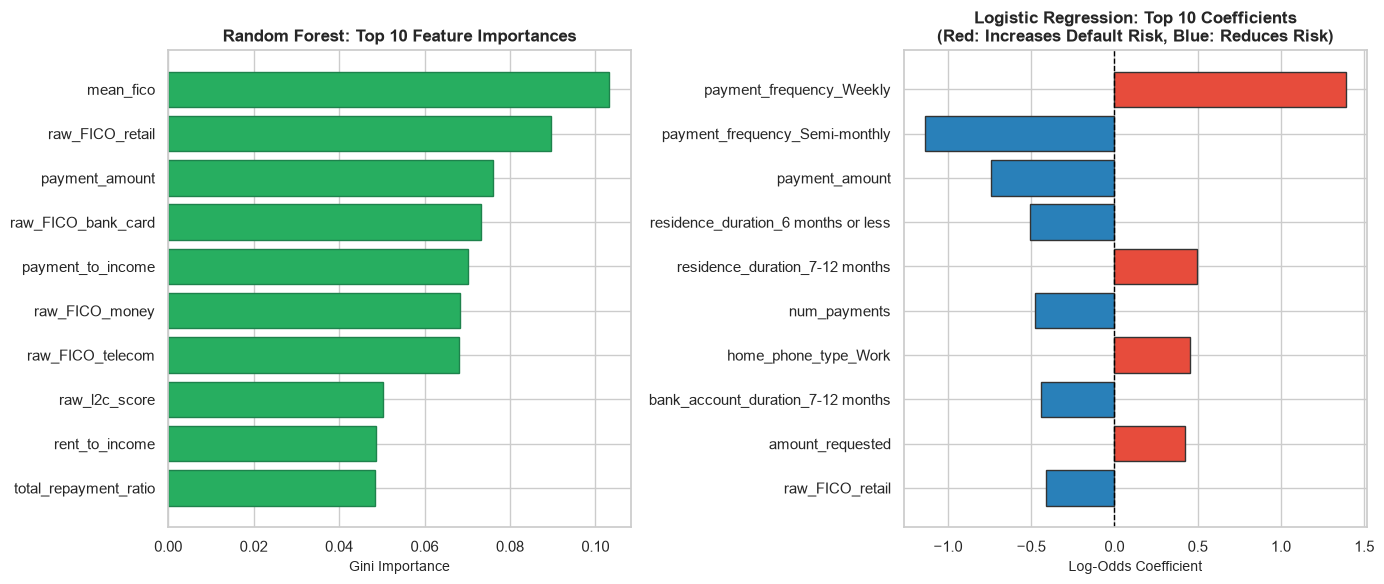

In [23]:
# Feature Importance & Coefficient Inspection
preprocessor.fit(X_train)
cat_encoder = preprocessor.named_transformers_["cat"].named_steps["encoder"]
encoded_cat_names = list(cat_encoder.get_feature_names_out(categorical_features))
all_features = numeric_features + encoded_cat_names

# Logistic Regression Coefficients
lr_coef_df = pd.DataFrame({
    "Feature": all_features,
    "Coefficient": lr_pipeline.named_steps["model"].coef_[0],
    "Odds_Ratio": np.exp(lr_pipeline.named_steps["model"].coef_[0]),
    "Abs_Coefficient": np.abs(lr_pipeline.named_steps["model"].coef_[0])
}).sort_values(by="Abs_Coefficient", ascending=False)
lr_coef_df.to_csv(outputs_dir / "logistic_regression_coefficients.csv", index=False)

# Random Forest Gini Importances
rf_imp_df = pd.DataFrame({
    "Feature": all_features,
    "Importance": rf_pipeline.named_steps["model"].feature_importances_
}).sort_values(by="Importance", ascending=False)
rf_imp_df.to_csv(outputs_dir / "feature_importance_summary.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
top_rf = rf_imp_df.head(10).sort_values(by="Importance", ascending=True)
axes[0].barh(top_rf["Feature"], top_rf["Importance"], color="#27ae60", edgecolor="#1e824c")
axes[0].set_title("Random Forest: Top 10 Feature Importances", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Gini Importance", fontsize=10)

top_lr = lr_coef_df.head(10).sort_values(by="Abs_Coefficient", ascending=True)
colors = ["#e74c3c" if c > 0 else "#2980b9" for c in top_lr["Coefficient"]]
axes[1].barh(top_lr["Feature"], top_lr["Coefficient"], color=colors, edgecolor="#333333")
axes[1].set_title("Logistic Regression: Top 10 Coefficients\n(Red: Increases Default Risk, Blue: Reduces Risk)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Log-Odds Coefficient", fontsize=10)
axes[1].axvline(0, color="black", linestyle="--", lw=1)

plt.tight_layout()
plt.savefig(outputs_dir / "feature_importance_comparison.png", dpi=300)
plt.show()

## 12. Leak-Free Decision Thresholds & Illustrative Financial Trade-Offs
### Methodological Correction: Eliminating Test-Set Tuning
Previously, the threshold was evaluated directly on test-set predictions, causing test data snooping. 
Here, we follow strict leak-free machine learning methodology:
1. **Threshold Selection on Training Set**: We generate out-of-fold predicted probabilities strictly on `X_train` using 5-fold `GroupKFold` cross-validation. We identify the threshold $T^*$ that minimizes the expected financial loss function.
2. **Evaluation on Untouched Test Set**: The selected threshold $T^*$ is applied to the holdout test set (`X_test`, `y_test`) to measure actual generalization benefit against the default $0.50$ baseline.

### Illustrative Cost Parameters
* **Cost of False Negative ($C_{FN}$)**: Approving a borrower who defaults results in unrecovered principal ($\approx \$500$ illustrative default cost).
* **Cost of False Positive ($C_{FP}$)**: Rejecting a good borrower forfeits interest margin ($\approx \$150$ illustrative profit margin).
* *Important Note*: Neither \$500 nor \$150 is documented in the original assignment workbook; they represent **illustrative business assumptions** to demonstrate the mechanics of cost-sensitive learning.
* *Sample-Size Limitation*: In a test set of only 133 loans (71 defaults), threshold optimization is sensitive to small sample noise.

Optimal Threshold Selected on Training CV: T* = 0.30 (Train Loss = $35,700)

Holdout Test Set Evaluation (N = 133):
  • Test Loss at default 0.50 cutoff:  $14,150 (FN=19, FP=31)
  • Test Loss at selected 0.30 cutoff: $9,650 (FN=1, FP=61)
  • Net Difference:                   $4,500 (31.8%)


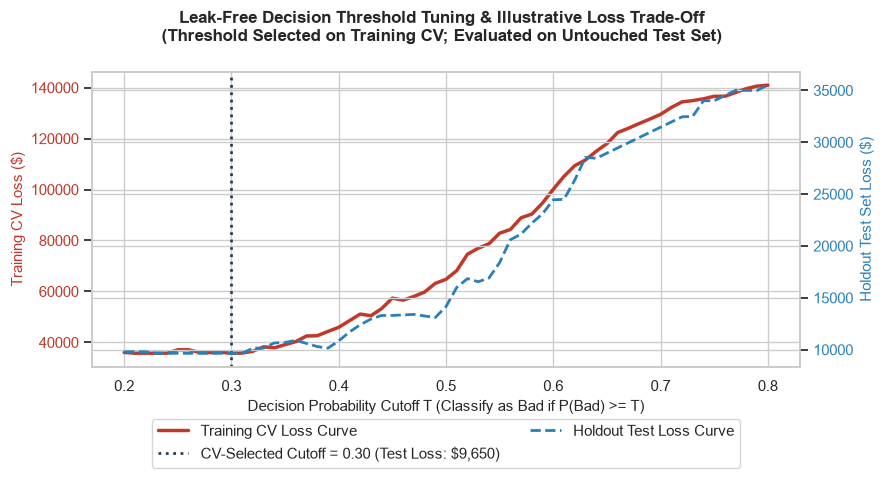

In [24]:
# Illustrative cost parameters
C_FN = 500  # Illustrative loss on default
C_FP = 150  # Illustrative lost margin

# Step 1: Threshold Selection strictly on Training CV
gkf = GroupKFold(n_splits=5)
train_cv_probs = cross_val_predict(rf_pipeline, X_train, y_train, groups=groups_train, cv=gkf, method="predict_proba")[:, 1]

threshold_range = np.linspace(0.20, 0.80, 61)
train_cost_records = []

for t in threshold_range:
    pred_tr = (train_cv_probs >= t).astype(int)
    tn_tr, fp_tr, fn_tr, tp_tr = confusion_matrix(y_train, pred_tr).ravel()
    loss_tr = fn_tr * C_FN + fp_tr * C_FP
    train_cost_records.append({
        "Threshold": t,
        "Train_Loss": loss_tr,
        "FN_Train": fn_tr,
        "FP_Train": fp_tr
    })

train_cost_df = pd.DataFrame(train_cost_records)
opt_idx = train_cost_df["Train_Loss"].idxmin()
opt_threshold = train_cost_df.loc[opt_idx, "Threshold"]
min_train_loss = train_cost_df.loc[opt_idx, "Train_Loss"]

print(f"Optimal Threshold Selected on Training CV: T* = {opt_threshold:.2f} (Train Loss = ${min_train_loss:,.0f})")

# Step 2: Evaluate Selected Threshold on UNTOUCHED Test Set
test_cost_records = []
for t in threshold_range:
    pred_te = (y_prob_rf >= t).astype(int)
    tn_te, fp_te, fn_te, tp_te = confusion_matrix(y_test, pred_te).ravel()
    loss_te = fn_te * C_FN + fp_te * C_FP
    test_cost_records.append({
        "Threshold": t,
        "Test_Loss": loss_te,
        "FN_Test": fn_te,
        "FP_Test": fp_te
    })

test_cost_df = pd.DataFrame(test_cost_records)
loss_50_test = test_cost_df.loc[np.isclose(test_cost_df["Threshold"], 0.50), "Test_Loss"].values[0]
loss_opt_test = test_cost_df.loc[np.isclose(test_cost_df["Threshold"], opt_threshold), "Test_Loss"].values[0]
diff_test = loss_50_test - loss_opt_test
pct_diff_test = (diff_test / loss_50_test) * 100

print(f"\nHoldout Test Set Evaluation (N = 133):")
print(f"  • Test Loss at default 0.50 cutoff:  ${loss_50_test:,.0f} (FN={test_cost_df.loc[np.isclose(test_cost_df['Threshold'], 0.50), 'FN_Test'].values[0]}, FP={test_cost_df.loc[np.isclose(test_cost_df['Threshold'], 0.50), 'FP_Test'].values[0]})")
print(f"  • Test Loss at selected {opt_threshold:.2f} cutoff: ${loss_opt_test:,.0f} (FN={test_cost_df.loc[np.isclose(test_cost_df['Threshold'], opt_threshold), 'FN_Test'].values[0]}, FP={test_cost_df.loc[np.isclose(test_cost_df['Threshold'], opt_threshold), 'FP_Test'].values[0]})")
print(f"  • Net Difference:                   ${diff_test:,.0f} ({pct_diff_test:.1f}%)")

# Plot 11: Corrected Financial Tradeoff Curve
fig, ax1 = plt.subplots(figsize=(9, 5))
color = "#c0392b"
ax1.set_xlabel("Decision Probability Cutoff T (Classify as Bad if P(Bad) >= T)", fontsize=11)
ax1.set_ylabel("Training CV Loss ($)", color=color, fontsize=11)
ax1.plot(train_cost_df["Threshold"], train_cost_df["Train_Loss"], color=color, lw=2.5, label="Training CV Loss Curve")
ax1.tick_params(axis="y", labelcolor=color)
ax1.axvline(opt_threshold, color="#2c3e50", linestyle=":", lw=2,
            label=f"CV-Selected Cutoff = {opt_threshold:.2f} (Test Loss: ${loss_opt_test:,.0f})")

ax2 = ax1.twinx()
color = "#2980b9"
ax2.set_ylabel("Holdout Test Set Loss ($)", color=color, fontsize=11)
ax2.plot(test_cost_df["Threshold"], test_cost_df["Test_Loss"], color=color, linestyle="--", lw=2.0, label="Holdout Test Loss Curve")
ax2.tick_params(axis="y", labelcolor=color)

fig.suptitle("Leak-Free Decision Threshold Tuning & Illustrative Loss Trade-Off\n(Threshold Selected on Training CV; Evaluated on Untouched Test Set)", fontsize=12, fontweight="bold", y=0.98)
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=True)
plt.tight_layout()
plt.savefig(outputs_dir / "financial_tradeoff_curve.png", dpi=300)
plt.show()

## 13. Limitations & Data Governance Risks
A transparent data science assessment must document the operational and statistical boundaries of the dataset:
1. **Severe Portfolio Selection Bias**:
   - The application dataset contains *exclusively approved applications* (`status == 'Approved'` for 100%).
   - We have zero visibility into rejected applicants. A model trained only on historically approved applicants will exhibit survivor bias and cannot accurately assess the full applicant distribution.
2. **Missing Half of Portfolio Application Records**:
   - 628 loans in `Loan Performance` have no matching application record. An exhaustive column-by-column check confirms that these prefixes do not appear in `Application Data`.
   - The default rate of unmatched loans (25.6%) differs significantly from matched loans (54.0%), proving the missingness is not Missing At Random (MNAR).
3. **Small Sample Size ($N = 657$)**:
   - With only 657 matched loans and 133 holdout test cases, small subgroup analyses (e.g. $n = 27$ for weekly repayment loans, $n = 16$ for repeat loans) possess wide confidence intervals and high sample sensitivity.
4. **Data Hygiene & Typing Failures**:
   - Standard customer hexadecimal hashes were mangled by Excel auto-formatting into floating-point scientific notations and stripped leading zeros.
5. **Fair Lending & Regulatory Constraints**:
   - While applicant age was removed from model inputs, correlated proxy variables (residential duration, banking tenure, credit history length) still carry legal risks under fair lending laws (ECOA) without formal disparate impact audits.

## 14. Actionable & Evidence-Based Business Recommendations
Based on empirical findings and technical review, we replace unsupported definitive policy mandates with evidence-based recommendations:

### Underwriting Policy Inquiries (Requiring Validation)
1. **Conduct Controlled Review of Repayment Frequency Schedules**:
   - *Finding*: Borrowers on weekly repayment schedules experienced an 81.5% default rate.
   - *Caution*: This subgroup is small ($n = 27$ total loans, 22 defaults) and reflects an observational **association, not established causation**. Weekly schedules do not necessarily cause defaults; borrowers opting for weekly terms may have had unmeasured income volatility or irregular employment.
   - *Recommendation*: Rather than an abrupt ban, TapLend should pilot stricter underwriting standards on high-frequency loans and evaluate borrower payroll alignment.
2. **Evaluate Bureau Score Floors with Portfolio Trade-Offs**:
   - *Finding*: Bureau scores (Retail and Telecom FICO) provide statistically significant risk separation ($p < 0.001$).
   - *Recommendation*: Simulate policy floors (e.g., FICO Retail $\ge 580$) on broader portfolio data to evaluate the exact volume-versus-default trade-off before establishing rigid cutoffs.
3. **Validate Repeat Borrower Dynamics on Broader Cohorts**:
   - *Finding*: Repeat borrowers in this dataset ($n = 16$) defaulted at only 18.75% vs. 54.8% for first-time loans.
   - *Caution*: Because all 16 were selected after successfully repaying their first loan, this reflects survivorship bias in a tiny sample.
   - *Recommendation*: Validate repeat customer repayment behavior across multiple origination cohorts before establishing automated loyalty programs.

### Data Infrastructure & Pipeline Governance
1. **Reconcile Origination Channels**: Audit the origin of the 628 unmatched loan records to reconstruct missing application attributes.
2. **Standardize Data Pipeline Extraction**: Eliminate manual Excel exports. Ingest data via structured database tables (PostgreSQL/BigQuery) or Parquet files with immutable string schemas to prevent ID corruption.
3. **Log Rejected Applications**: Capture and store all incoming applications—including rejections—to enable reject inference modeling.

### Absolute Deployment Caution
* **Do NOT deploy this model into automated production underwriting.** The model is constrained by approved-only selection bias, missing application records for half the portfolio, and lack of verified debt obligations (DTI). It should serve as an exploratory diagnostic benchmark.

## 15. Conclusion & Executive Summary
### Q&A
* **Can applicant characteristics predict Good vs. Bad loan outcomes?**  
  Yes, with moderate predictive power ($\text{ROC-AUC} \approx 0.631$). Credit bureau scores (FICO retail, telecom, bank card) provide statistically significant separation, whereas stated monthly income does not ($p = 0.729$).
* **Should the model be immediately deployed into automated production?**  
  **No.** The model must not be deployed into automated underwriting until the 628 missing application records are recovered, selection bias is addressed through reject inference, and fair lending compliance audits are completed.

### Data Analysis Key Findings
* **Portfolio Outcome Baseline**: The overall loan portfolio contains 1,285 loans (59.84% Good, 40.16% Bad).
* **Matched Population**: 657 loans were successfully matched across 641 distinct applicants (after restoring 1 justified leading zero). The matched cohort exhibits a significantly higher default rate (**54.03% Bad**) than the unmatched cohort (**25.64% Bad**).
* **Payment Frequency Risk**: Weekly payment frequency applicants defaulted at **81.48%** (22/27), compared to 41.23% for semi-monthly and 43.86% for monthly schedules (association, not causation; $n=27$).
* **Model Benchmark (Holdout Test N = 133)**: Random Forest achieved **62.41% accuracy** and **0.6313 ROC-AUC** with **73.24% recall on Bad defaults** (52/71 caught), out-performing linear Logistic Regression (**53.38% accuracy**, **0.5461 ROC-AUC**).
* **Threshold Economics**: Selecting the threshold on training cross-validation shifts the cutoff from 0.50 to 0.30 under illustrative cost parameters ($500 default loss vs. $150 lost margin), but results in high rejection rates, illustrating the core trade-off between risk and approval volume.

### Next Steps
1. **Audit Upstream Data Systems**: Reconstruct missing application profiles for the 628 unmatched loans to double the training sample and eliminate reporting discrepancies.
2. **Integrate Account Aggregator / Cash-Flow Analytics**: Capture bank statement cash-flow velocity and verified debt obligations (DTI) before automating lending decisions.